In [1]:
import pandas as pd
import glob
# Initialize empty dataframe
df = pd.DataFrame()
folder = 'modeling_n24'
# Get all distribution files
files = glob.glob(f'files/{folder}/distr_temperature_*_pressure_*_N_*_diffusion_*_stream_*_particleSize_*_cat_conc_*.pkl')

failed_runs = []

for file in files:
    # Extract parameters from filename
    params = file.split('_')
    temperature = float(params[params.index('temperature')+1])

    pressure = float(params[params.index('pressure')+1])
    N = int(params[params.index('N')+1])
    diffusion = params[params.index('diffusion')+1] == 'True'
    stream = params[params.index('stream')+1] == 'True'
    ps = int(params[params.index('particleSize')+1])
    cat_conc = float(params[params.index('conc')+1][:-4])
    # Read distribution file
    distr = pd.read_pickle(file)
    # Add parameters as columns
    distr['temperature'] = temperature
    distr['pressure'] = pressure
    distr['N'] = N
    distr['diffusion'] = diffusion
    distr['is_stream'] = stream
    distr['particle_size'] = ps
    distr['cat_conc'] = cat_conc
    
    # Append to main dataframe
    df = pd.concat([df, distr], ignore_index=True)
df = df.drop_duplicates()
dft = df.groupby(['temperature', 'pressure', 'N', 'is_stream', 'diffusion', 'particle_size', 'cat_conc']).count().reset_index()
df=df.sort_values(['pressure', 'temperature', 'n'])

df.info()#3552 3744

<class 'pandas.core.frame.DataFrame'>
Index: 3756 entries, 12 to 3719
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   n              3756 non-null   int64  
 1   concentration  3756 non-null   float64
 2   probability    3443 non-null   float64
 3   temperature    3756 non-null   float64
 4   pressure       3756 non-null   float64
 5   N              3756 non-null   int64  
 6   diffusion      3756 non-null   bool   
 7   is_stream      3756 non-null   bool   
 8   particle_size  3756 non-null   int64  
 9   cat_conc       3756 non-null   float64
dtypes: bool(2), float64(5), int64(3)
memory usage: 271.4 KB


In [2]:
# remove n=2
df = df[df.n != 2].copy()

# expectation terms
df['exp_n']  = df['probability'] * df['n']
df['exp_n2'] = df['probability'] * (df['n'] ** 2)

# group by and aggregate
df_grouped = (df.groupby(
        ['temperature', 'pressure', 'is_stream', 'diffusion', 'particle_size', 'cat_conc'],
        as_index=False
    )
    .agg(expected_n=('exp_n','sum'),
         expected_n2=('exp_n2','sum'))
)

# variance and standard deviation
df_grouped['variance_n'] = df_grouped['expected_n2'] - df_grouped['expected_n']**2
df_grouped['std_n'] = df_grouped['variance_n']**0.5
df_grouped['coefficient_variance'] = df_grouped.std_n/df_grouped.expected_n
# df_grouped = df_grouped[df.coefficient_variance < ]
df_grouped.coefficient_variance.describe(), df_grouped.expected_n.describe()

(count    311.000000
 mean       0.211747
 std        0.091247
 min        0.000866
 25%        0.129518
 50%        0.220024
 75%        0.283582
 max        0.418008
 Name: coefficient_variance, dtype: float64,
 count    313.000000
 mean      12.525272
 std        4.907341
 min        5.930348
 25%        9.075890
 50%       11.611075
 75%       13.892472
 max       23.999965
 Name: expected_n, dtype: float64)

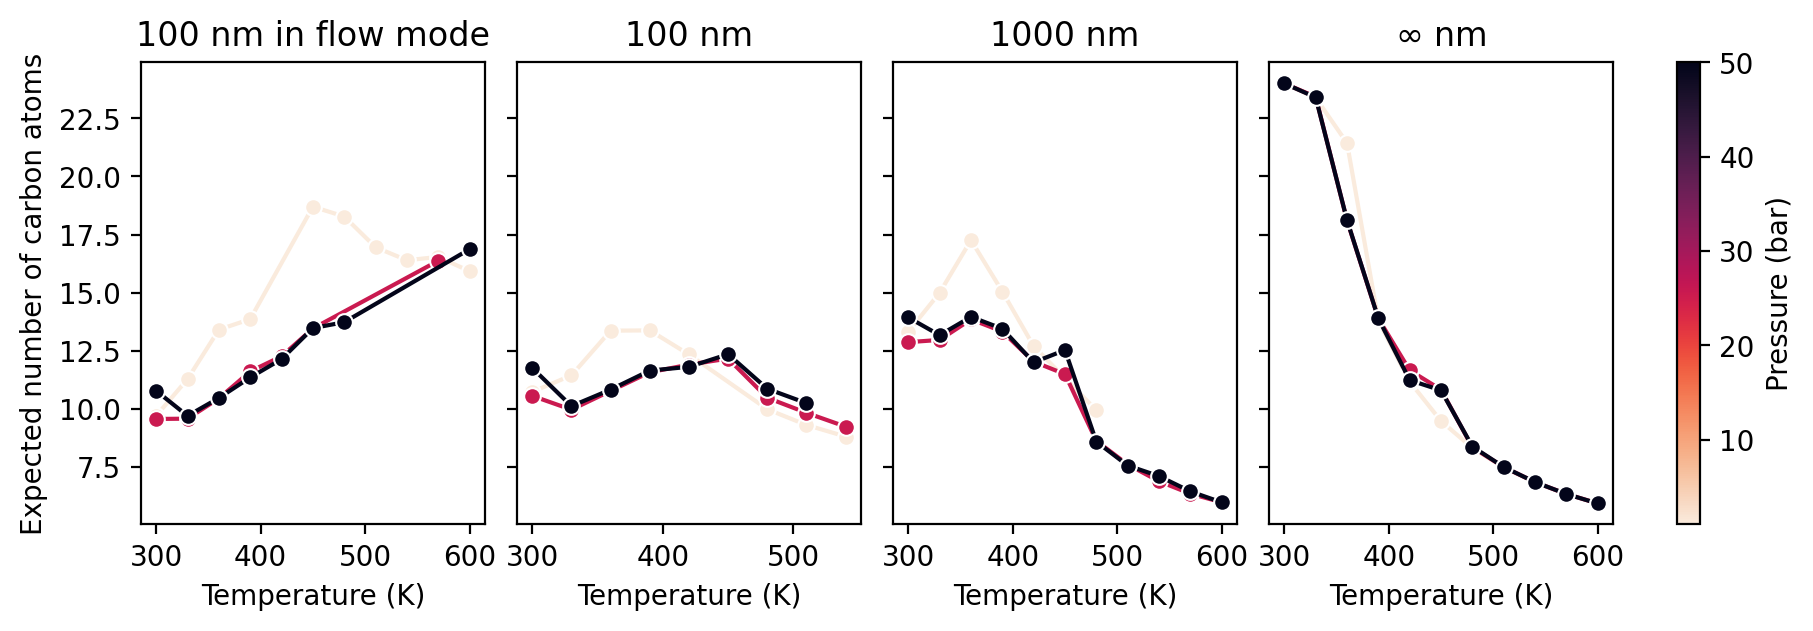

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (100, True, axs[1]),
    (1000, True, axs[2]),
    (100, False, axs[3])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='expected_n', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 100')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='expected_n', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('100 nm in flow mode', '100 nm', '1000 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('Expected number of carbon atoms')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_ps.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_ps.svg", bbox_inches="tight")

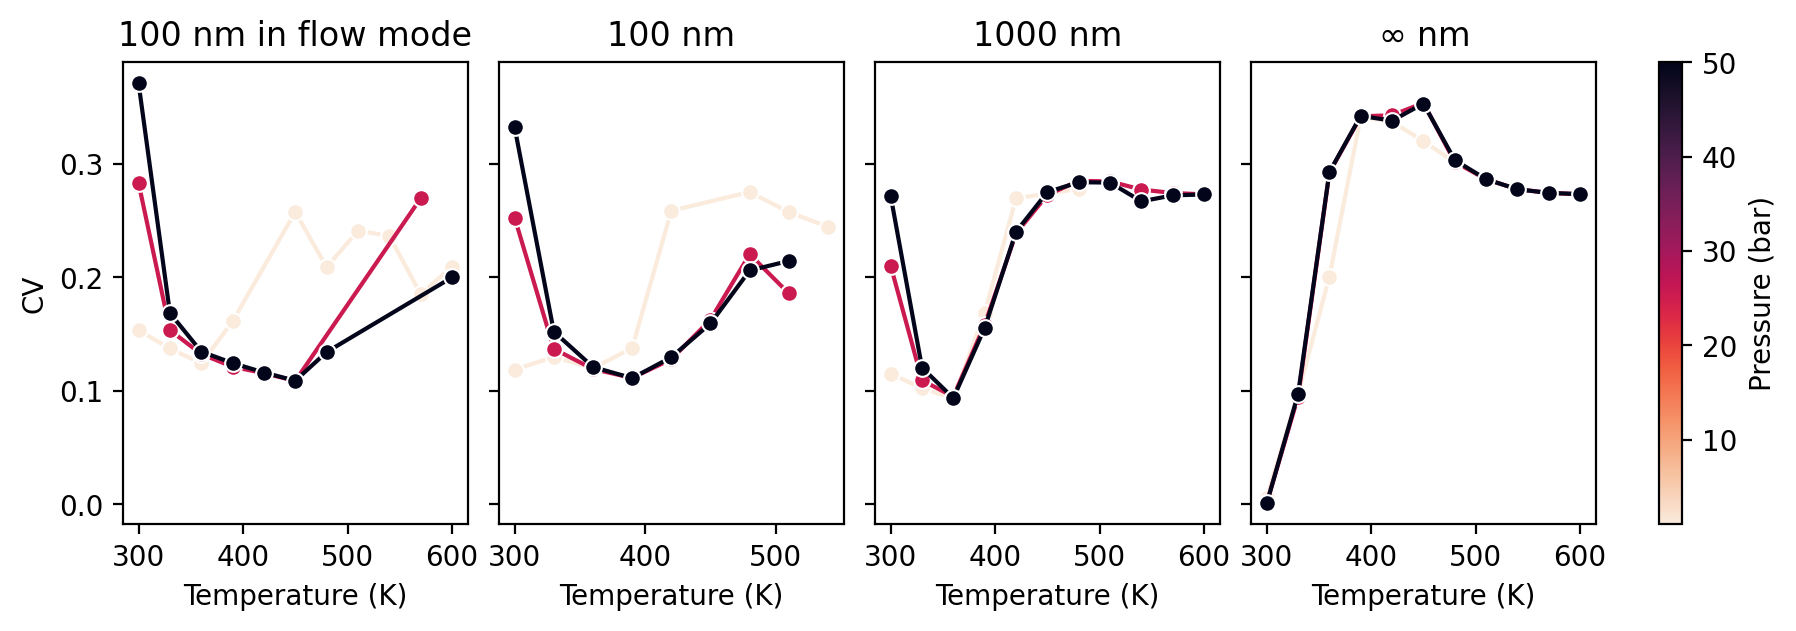

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl

fig, axs = plt.subplots(1, 4, figsize=(10, 3), dpi=200, sharey=True)

dft = df_grouped.query('cat_conc == 0.01 and not is_stream')

cmap = "rocket_r"
norm = mpl.colors.Normalize(vmin=1, vmax=50)

# Update all lineplots to use the same colormap and normalization for pressure
for i, (psize, diff, ax) in enumerate([
    (100, True, axs[1]),
    (1000, True, axs[2]),
    (100, False, axs[3])
]):
    data = dft.query(f'particle_size == {psize} and {"diffusion" if diff else "not diffusion"}')
    sns.lineplot(
        data=data,
        x='temperature', y='coefficient_variance', hue='pressure',
        marker='o', ax=ax,
        palette=sns.color_palette(cmap, as_cmap=True),
        hue_norm=norm
    )
data=df_grouped.query('is_stream and is_stream and cat_conc == 0.01 and particle_size == 100')
data = data.sort_values(by=['pressure', 'temperature'])
sns.lineplot(
    data=data,
    x='temperature', y='coefficient_variance', hue='pressure',
    marker='o', ax=axs[0],
    palette=sns.color_palette(cmap, as_cmap=True),
    hue_norm=norm
)


for title, ax in zip(('100 nm in flow mode', '100 nm', '1000 nm', r'$\infty$ nm'), axs):
    ax.set_xlabel('Temperature (K)')
    box = ax.get_position()
    ax.set_position([box.x0, box.y0, box.width * 1.1, box.height])
    handles, labels = ax.get_legend_handles_labels()
    ax.legend().remove()
    ax.set_title(title)

axs[0].set_ylabel('CV')

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = fig.colorbar(sm, ax=axs, orientation='vertical', fraction=0.03, pad=0.04)
cbar.set_label('Pressure (bar)')

fig.savefig("files/plots/distribution_CV.pdf", bbox_inches="tight")
fig.savefig("files/plots/distribution_CV.svg", bbox_inches="tight")